In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adagrad

In [2]:
X, y = load_breast_cancer(return_X_y=True)
y_svm = y * 2 - 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y_svm, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [3]:
model = Sequential([
    Dense(
        1,
        input_shape=(X_train_s.shape[1],),
        activation="linear",
        kernel_regularizer="l2",
    )
])
model.compile(optimizer=Adagrad(learning_rate=0.05), loss="hinge")

history = model.fit(
    X_train_s, y_train, epochs=100, batch_size=32, verbose=0
)

c:\Users\VICTUS\Desktop\مواد\الفصل الاول\ML\ML-ASS\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy (Adagrad): 0.9824561403508771


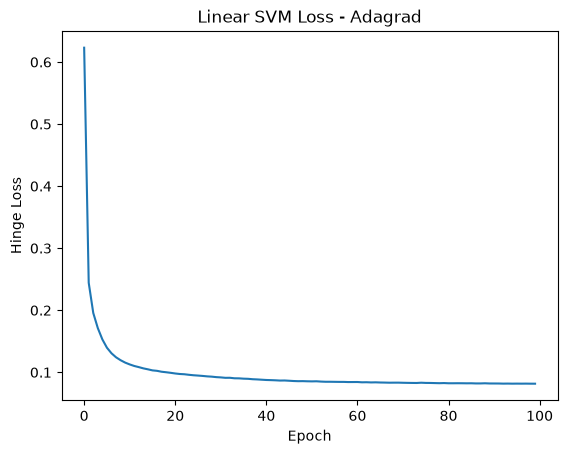

In [4]:
preds = (model.predict(X_test_s, verbose=0).ravel() >= 0) * 2 - 1
print("Accuracy (Adagrad):", accuracy_score(y_test, preds))

plt.plot(history.history["loss"])
plt.title("Linear SVM Loss - Adagrad")
plt.xlabel("Epoch")
plt.ylabel("Hinge Loss")
plt.show()